# Olympic Athletes: 120 Years of History

## 1. Dataset Selection
**Dataset:** 120 years of Olympic history: athletes and results



**Source:** Kaggle (heesoo37), originally scraped from sports-reference.com. Covers Athens 1896 to Rio 2016.



**Why I chose it:** I'm interested in sport, and the data is realistically messy. Height, weight and age are missing for many athletes mainly more towards the earlier records, and medal is null for everyone who didn't win one. That makes it a good test of cleaning decisions.

**Questions to explore:**
1. How has female participation changed over time?
2. How have athletes' height and weight changed over time, and do they differ by sport?
3. Which countries have won the most medals, and does this change by era?
4. How does athlete age vary by sport?
5. Do host countries win more medals than usual (home advantage)?

### 2. Initial Data Exploration and Understanding

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

athletes = pd.read_csv("../data/raw/athlete_events.csv")
regions = pd.read_csv("../data/raw/noc_regions.csv")

print("Athletes:", athletes.shape)
print("Regions:", regions.shape)

Athletes: (271116, 15)
Regions: (230, 3)


In [6]:
athletes.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [7]:
print("Columns:", list(athletes.columns))
athletes.info()

Columns: ['ID', 'Name', 'Sex', 'Age', 'Height', 'Weight', 'Team', 'NOC', 'Games', 'Year', 'Season', 'City', 'Sport', 'Event', 'Medal']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  object 
 2   Sex     271116 non-null  object 
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  object 
 7   NOC     271116 non-null  object 
 8   Games   271116 non-null  object 
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  object 
 11  City    271116 non-null  object 
 12  Sport   271116 non-null  object 
 13  Event   271116 non-null  object 
 14  Medal   39783 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 31.0+ MB


In [12]:
missing = pd.DataFrame({
    "missing": athletes.isna().sum(),
    "percent": (athletes.isna().mean() * 100).round(2)
}).sort_values("percent", ascending=False)
missing

,missing,percent
Medal,231333,85.33
Weight,62875,23.19
Height,60171,22.19
Age,9474,3.49
Sex,0,0.00
ID,0,0.00
Name,0,0.00
Team,0,0.00
NOC,0,0.00
Year,0,0.00


In [13]:
display(athletes.describe().round(2))
print("Duplicate rows:", athletes.duplicated().sum())
print("Years:", athletes["Year"].min(), "to", athletes["Year"].max())
print("Seasons:", athletes["Season"].unique())

,ID,Age,Height,Weight,Year
count,271116.00,261642.00,210945.00,208241.00,271116.00
mean,68248.95,25.56,175.34,70.70,1978.38
std,39022.29,6.39,10.52,14.35,29.88
min,1.00,10.00,127.00,25.00,1896.00
25%,34643.00,21.00,168.00,60.00,1960.00
50%,68205.00,24.00,175.00,70.00,1988.00
75%,102097.25,28.00,183.00,79.00,2002.00
max,135571.00,97.00,226.00,214.00,2016.00


Duplicate rows: 1385
Years: 1896 to 2016
Seasons: ['Summer' 'Winter']


In [14]:
regions.head()

,NOC,region,notes
0,AFG,Afghanistan,NaN
1,AHO,Curacao,Netherlands Antilles
2,ALB,Albania,NaN
3,ALG,Algeria,NaN
4,AND,Andorra,NaN


## 3. Data Cleaning

### Decision explanations

| Issue | Finding | Decision | Reason |
|---|---|---|---|
| Duplicate rows | 1,385 exact duplicates | Drop them | Same athlete, same event, same Games recorded twice. They would inflate counts and medal totals. |
| Medal nulls (85%) | Null means no medal | Recode to "No Medal" and add a `Won_Medal` flag | These are not missing data. Leaving them as NaN would hide non-medallists from groupby counts. |
| Height / Weight / Age missing | 22% / 23% / 3.5% | Do not impute. Leave as NaN and drop per-question only | Missingness is concentrated in older Games, so filling with averages would invent modern-looking athletes in 1900. Dropping per question keeps the rest of each row usable. |
| Art Competitions | Non-athletic events with odd ages and no body measurements | Remove | Not physical sport, and they distort age and physique analysis. |
| Country names | `NOC` codes only | Merge `noc_regions.csv` to get country names, fall back to `Team` where there is no match | Readable charts. |
| Data types | Text columns stored as object, Age as float | Convert to category / nullable integer | Less memory, clearer intent. |
| Repeated athlete/Games/Event (95) | Mostly 1900 sailing/rowing: one athlete in several boats | Keep | Genuine separate entries, not errors. |
| BMI < 13 (24 rows) | Physically implausible, e.g. 160 cm / 32 kg | Set Height, Weight and BMI to NaN | Can't tell which measurement is wrong. |
| BMI > 45 (50 rows) | Mostly weightlifting, judo, wrestling | Keep | Plausible for super-heavyweight athletes. |
| NOC `SGP` | Team column holds boat names | Set Country to "Singapore" explicitly | The Team fallback gave wrong values. |

In [15]:
df = athletes.copy()   # duplicated incase i mess anything up and would like a extra version and is good for comprison

# Dups
print("Rows before:", len(df))
df = df.drop_duplicates()
print("Rows after: ", len(df), "| removed:", len(athletes) - len(df))

# Same athlete listed twice for the same event at the same olympicGames 
print("Same athlete/Games/Event repeats:", df.duplicated(subset=["ID", "Games", "Event"]).sum())

# Art Competitions - didnt want these involved as im not interested in them and do not demonstratre athletic ability
art = df["Sport"] == "Art Competitions"
print("Art Competitions rows:", art.sum(), "| years:", df.loc[art, "Year"].min(), "-", df.loc[art, "Year"].max())
df = df[~art]
print("Rows now:", len(df))

Rows before: 271116
Rows after:  269731 | removed: 1385
Same athlete/Games/Event repeats: 95
Art Competitions rows: 2263 | years: 1912 - 1948
Rows now: 267468


In [16]:
# Is missingness random cehck
df["Decade"] = df["Year"] // 10 * 10
(df[["Age", "Height", "Weight"]].isna().groupby(df["Decade"]).mean().mul(100).round(1))

,Age,Height,Weight
Decade,,,
1890,42.9,87.9,87.1
1900,30.3,86.8,88.6
1910,3.7,82.0,85.1
1920,19.1,81.3,87.0
1930,3.7,73.1,83.0
1940,15.7,83.3,83.6
1950,5.8,69.1,69.2
1960,1.4,6.1,6.6
1970,0.7,5.2,5.8


In [23]:
#  null means no medal
df["Medal"] = df["Medal"].fillna("No Medal")
df["Medal"] = pd.Categorical(df["Medal"], categories=["No Medal", "Bronze", "Silver", "Gold"], ordered=True) #very useful for searching for people who
df["Won_Medal"] = df["Medal"] != "No Medal"                                                              # ahve medals greater then silver i.e
                                                                                                        # df["Medal"] >= "Silver" works
#  body measurements
df["BMI"] = (df["Weight"] / (df["Height"] / 100) ** 2).round(1)
print("BMI < 13 or > 45:", ((df["BMI"] < 13) | (df["BMI"] > 45)).sum())
df["BMI"].describe().round(1)

BMI < 13 or > 45: 50


count    206800.0
mean         22.8
std           2.9
min          13.3
25%          21.0
50%          22.5
75%          24.2
max          63.9
Name: BMI, dtype: float64

In [18]:
# Country names
assert regions["NOC"].is_unique
n = len(df)
df = df.merge(regions[["NOC", "region"]], on="NOC", how="left")
assert len(df) == n   # merge must not add rows quite useful for later a

unmatched = df.loc[df["region"].isna(), "NOC"].unique()
print("NOC codes with no region:", unmatched)
df["region"] = df["region"].fillna(df["Team"])
df = df.rename(columns={"region": "Country"})

# convert types
for col in df.select_dtypes("object").columns:
    df[col] = df[col].str.strip()

df["Age"] = df["Age"].astype("Int64")
for col in ["Sex", "Season", "Sport", "Country", "NOC"]:
    df[col] = df[col].astype("category")

df.info()

NOC codes with no region: ['SGP' 'ROT' 'TUV']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267468 entries, 0 to 267467
Data columns (total 19 columns):
 #   Column     Non-Null Count   Dtype   
---  ------     --------------   -----   
 0   ID         267468 non-null  int64   
 1   Name       267468 non-null  object  
 2   Sex        267468 non-null  category
 3   Age        258533 non-null  Int64   
 4   Height     210885 non-null  float64 
 5   Weight     208185 non-null  float64 
 6   Team       267468 non-null  object  
 7   NOC        267468 non-null  category
 8   Games      267468 non-null  object  
 9   Year       267468 non-null  int64   
 10  Season     267468 non-null  category
 11  City       267468 non-null  object  
 12  Sport      267468 non-null  category
 13  Event      267468 non-null  object  
 14  Medal      267468 non-null  category
 15  Decade     267468 non-null  int64   
 16  Won_Medal  267468 non-null  bool    
 17  BMI        206824 non-null  float64 
 18

In [19]:

from pathlib import Path
Path("../data/processed").mkdir(parents=True, exist_ok=True)
df.to_csv("../data/processed/olympics_clean.csv", index=False)

print(df.shape)

(267468, 19)


In [26]:
# Repeated athlete/Games/Event rows
rep = df[df.duplicated(subset=["ID", "Games", "Event"], keep=False)].sort_values(["ID", "Games", "Event"])
display(rep[["ID", "Name", "Games", "Sport", "Event", "Team", "Age", "Height", "Weight", "Medal"]].head(12))
print("sports", rep["Sport"].value_counts().head(5).to_dict())

#Extreme BMI values were seen as ow as 8.4 which isnt realistic meaning there was some form of entry error going on which needed to be fixed
low = df[df["BMI"] < 13]
high = df[df["BMI"] > 45]
print("BMI < 13:", len(low), "| BMI > 45:", len(high))
display(low[["Name", "Sport", "Year", "Height", "Weight", "BMI"]].head(8))
print("BMI > 45 by sport:", high["Sport"].value_counts().head(6).to_dict())

,ID,Name,Games,Sport,Event,Team,Age,Height,Weight,Medal
4005,2317,Auguste Albert,1900 Summer,Sailing,Sailing Mixed 1-2 Ton,Martha-1,<NA>,NaN,NaN,Silver
4006,2317,Auguste Albert,1900 Summer,Sailing,Sailing Mixed 1-2 Ton,Martha-1,<NA>,NaN,NaN,Bronze
10840,5959,Louis Albert Auguste-Dormeuil (Dormeuil-),1900 Summer,Sailing,Sailing Mixed 0.5-1 Ton,Pettit-Poucet-6,31,NaN,NaN,No Medal
10841,5959,Louis Albert Auguste-Dormeuil (Dormeuil-),1900 Summer,Sailing,Sailing Mixed 0.5-1 Ton,Carabinier-15,31,NaN,NaN,Gold
15978,8683,Jacques Baudrier,1900 Summer,Sailing,Sailing Mixed 0.5-1 Ton,Crabe II-1,28,NaN,NaN,Silver
15979,8683,Jacques Baudrier,1900 Summer,Sailing,Sailing Mixed 0.5-1 Ton,Crabe II-4,28,NaN,NaN,Bronze
15980,8683,Jacques Baudrier,1900 Summer,Sailing,Sailing Mixed 1-2 Ton,Nina Claire-2,28,NaN,NaN,Bronze
15981,8683,Jacques Baudrier,1900 Summer,Sailing,Sailing Mixed 1-2 Ton,Nina Claire-2,28,NaN,NaN,No Medal
15976,8683,Jacques Baudrier,1900 Summer,Sailing,Sailing Mixed Open,Crabe II-12,28,NaN,NaN,No Medal
15977,8683,Jacques Baudrier,1900 Summer,Sailing,Sailing Mixed Open,Nina Claire-30,28,NaN,NaN,No Medal


sports {'Sailing': 101, 'Rowing': 28, 'Equestrianism': 8, 'Cycling': 6, 'Polo': 2}
BMI < 13: 0 | BMI > 45: 50


,Name,Sport,Year,Height,Weight,BMI


BMI > 45 by sport: {'Weightlifting': 34, 'Judo': 9, 'Wrestling': 5, 'Shooting': 1, 'Boxing': 1, 'Aeronautics': 0}


In [22]:
# Singapore Team holds boat names, so set the country specifically fior them
df["Country"] = df["Country"].astype(object)
df.loc[df["NOC"] == "SGP", "Country"] = "Singapore"
df["Country"] = df["Country"].astype("category")
print(df.loc[df["NOC"] == "SGP", "Country"].astype(str).unique())

# Implausible BMI < 13 can't tell which measurement is wrong, so null all three
bad = df["BMI"] < 13
print("Rows nulled:", bad.sum())
df.loc[bad, ["Height", "Weight", "BMI"]] = np.nan

df.to_csv("../data/processed/olympics_clean.csv", index=False)
print(df.shape)

['Singapore']
Rows nulled: 24
(267468, 19)


In [24]:
display(df.loc[df["Name"] == "Marta Artigas y Masdeu", ["Height", "Weight", "BMI"]].head(2))  # after the BMI < 13 CHANGE these are NaN
display(df[["Height", "Weight", "BMI"]].dropna().head(3))
print(df["Medal"].dtype)
print(df["Medal"].cat.categories.tolist())
print(df["Medal"].value_counts())
print(df["Won_Medal"].mean().round(3))

,Height,Weight,BMI
9764,NaN,NaN,NaN
9765,NaN,NaN,NaN


,Height,Weight,BMI
0,180.0,80.0,24.7
1,170.0,60.0,20.8
4,185.0,82.0,24.0


category
['No Medal', 'Bronze', 'Silver', 'Gold']
Medal
No Medal    227852
Gold         13320
Bronze       13244
Silver       13052
Name: count, dtype: int64
0.148


In [25]:
Path("../data/processed").mkdir(parents=True, exist_ok=True)
df.to_csv("../data/processed/olympics_clean.csv", index=False)

## 4. Data Analysis

1. How has female participation at the Summer Olympics changed over time?
2. How have athletes' height, weight and BMI changed since 1960, and how does physique differ by sport?
3. Which countries have won the most medals, and does that change by era?
4. Which sports have the youngest and oldest athletes?
5. Do host countries win a bigger share of medals when they host?

In [27]:
# One row per athlete per Games 
people = df.drop_duplicates(subset=["ID", "Games"])
summer_people = people[people["Season"] == "Summer"]

# One row per medal for medal counts, a team medal counts once and doesnt count every player in the team
medals = df[df["Won_Medal"]].drop_duplicates(subset=["Games", "Event", "Medal", "NOC"]).copy()

print("Athlete-event rows:", len(df))
print("Athlete-Games rows:", len(people))
print("Medals awarded:", len(medals))

Athlete-event rows: 267468
Athlete-Games rows: 185410
Medals awarded: 18758


# Q1: female participation

In [28]:
# Number of different women + total athletes at each Summer olympcs
women = summer_people[summer_people["Sex"] == "F"].groupby("Year")["ID"].nunique()
everyone = summer_people.groupby("Year")["ID"].nunique()

# Percentage female ---- years with no women give NaN, so fill with 0
pct_female = (women / everyone * 100).fillna(0).round(1)

print("First Games with women:", pct_female[pct_female > 0].index.min())
pct_female.loc[[1900, 1920, 1960, 1980, 2000, 2016]]

First Games with women: 1900


Year
1900     1.9
1920     2.9
1960    11.5
1980    21.4
2000    38.2
2016    45.0
Name: ID, dtype: float64

# Q2: physique since 1960

In [29]:
# Keep athletes with both height and weight, from 1960 onwards as early data is missing a lot of info
phys = summer_people.dropna(subset=["Height", "Weight"])
phys = phys[phys["Year"] >= 1960]

# Average height, weight and BMI by decade and sex
trend = phys.groupby(["Decade", "Sex"], observed=True)[["Height", "Weight", "BMI"]].mean().round(1)
trend

Height  Weight   BMI
Decade Sex                      
1960   F     166.5    60.0  21.6
       M     177.0    73.8  23.5
1970   F     168.6    60.7  21.2
       M     178.5    75.5  23.6
1980   F     169.7    61.2  21.1
       M     179.5    76.2  23.5
1990   F     169.9    61.3  21.1
       M     181.0    78.2  23.7
2000   F     170.2    62.6  21.5
       M     181.8    79.4  23.9
2010   F     170.2    62.7  21.5
       M     182.3    79.8  23.9

In [30]:
# Physique by sport all seasons, 1960+
all_phys = people.dropna(subset=["Height", "Weight"])
all_phys = all_phys[all_phys["Year"] >= 1960]

by_sport = all_phys.groupby("Sport", observed=True).agg(
    athletes=("ID", "size"),
    height=("Height", "mean"),
    weight=("Weight", "mean"),
).round(1)

# Only compare sports with at least 500 athletes, so averages are reliable
by_sport = by_sport[by_sport["athletes"] >= 500].sort_values("height")

print("Shortest sports:")
display(by_sport.head(5))
print("Tallest sports:")
display(by_sport.tail(5))

Shortest sports:


,athletes,height,weight
Sport,,,
Gymnastics,2758,161.9,55.5
Diving,1470,166.6,60.5
Weightlifting,2875,167.7,79.5
Rhythmic Gymnastics,615,167.8,48.8
Figure Skating,1426,168.2,59.6


Tallest sports:


,athletes,height,weight
Sport,,,
Rowing,7346,184.5,80.4
Water Polo,2643,185.1,84.6
Beach Volleyball,538,186.2,79.1
Volleyball,3276,187.0,78.9
Basketball,3499,191.4,85.9


# Q3: medals by country and era

In [31]:

medals["Country"].value_counts().head(10) #top10 nations

Country
USA          2814
Russia       1916
Germany      1742
UK            910
France        866
Italy         708
Sweden        653
China         598
Australia     531
Hungary       506
Name: count, dtype: int64

In [32]:
# Split history into three eras
medals["Era"] = pd.cut(medals["Year"], bins=[1895, 1944, 1991, 2016],
                       labels=["1896-1944", "1945-1991", "1992-2016"])

# Medals per country per era
era_counts = medals.groupby(["Era", "Country"], observed=True).size().reset_index(name="medals")

# Top 5 in each era
for era in ["1896-1944", "1945-1991", "1992-2016"]:
    print(era)
    display(era_counts[era_counts["Era"] == era].nlargest(5, "medals")[["Country", "medals"]])

1896-1944


,Country,medals
42,USA,869
41,UK,397
14,France,332
38,Sweden,284
15,Germany,240


1945-1991


,Country,medals
105,Russia,1197
124,USA,1049
69,Germany,930
73,Hungary,285
80,Italy,277


1992-2016


,Country,medals
245,USA,896
221,Russia,711
169,Germany,572
150,China,538
166,France,323


# Q4: age by sport

I use the median here because a few very old competitors can pull the mean up which skews data 

In [34]:
age = people.dropna(subset=["Age"]).copy()
age["Age"] = age["Age"].astype(float)     # convert back to normal numbers for the maths

age_by_sport = age.groupby("Sport", observed=True)["Age"].agg(["count", "median", "mean"]).round(1)
age_by_sport = age_by_sport[age_by_sport["count"] >= 300].sort_values(["median", "mean"])

print("Youngest sports:")
display(age_by_sport.head(5))
print("Oldest sports:")
display(age_by_sport.tail(5))    

Youngest sports:


,count,median,mean
Sport,,,
Rhythmic Gymnastics,658,18.0,18.7
Swimming,11462,20.0,20.7
Figure Skating,2160,22.0,22.1
Diving,2055,22.0,22.4
Synchronized Swimming,726,22.0,22.4


Oldest sports:


,count,median,mean
Sport,,,
Beach Volleyball,564,29.0,29.1
Sailing,6200,29.0,30.2
Curling,463,30.0,31.4
Shooting,7023,32.0,33.1
Equestrianism,3403,33.0,34.3


# Q5: home advantage

I’ve simplified this a lot and limited it to Summer Games

In [35]:
host_games = {
    "1896 Summer": "GRE", "1900 Summer": "FRA", "1904 Summer": "USA", "1908 Summer": "GBR",
    "1912 Summer": "SWE", "1920 Summer": "BEL", "1924 Summer": "FRA", "1928 Summer": "NED",
    "1932 Summer": "USA", "1936 Summer": "GER", "1948 Summer": "GBR", "1952 Summer": "FIN",
    "1956 Summer": "AUS", "1960 Summer": "ITA", "1964 Summer": "JPN", "1968 Summer": "MEX",
    "1972 Summer": "FRG", "1976 Summer": "CAN", "1980 Summer": "URS", "1984 Summer": "USA",
    "1988 Summer": "KOR", "1992 Summer": "ESP", "1996 Summer": "USA", "2000 Summer": "AUS",
    "2004 Summer": "GRE", "2008 Summer": "CHN", "2012 Summer": "GBR", "2016 Summer": "BRA",
}
# IMPORTNAT NOTE 1956 equestrian was held in Stockholm, but nearly all events were in Melbourne.

In [36]:
summer_medals = medals[medals["Season"] == "Summer"]

# Medals won by each country at each Games
medal_counts = (summer_medals.astype({"NOC": str})
                .groupby(["Games", "NOC"]).size().reset_index(name="medals"))

# Total medals awarded at each Games
games_total = summer_medals.groupby("Games").size().reset_index(name="total")

# Every country that entered each Games including those with n0 medals
entered = summer_people[["Games", "NOC"]].astype({"NOC": str}).drop_duplicates()

share = entered.merge(medal_counts, on=["Games", "NOC"], how="left")
share["medals"] = share["medals"].fillna(0)
share = share.merge(games_total, on="Games")
share["share"] = share["medals"] / share["total"] * 100

In [37]:
results = []
for games, host in host_games.items():
    
    host_row = share[(share["Games"] == games) & (share["NOC"] == host)]

    # The same country's share at the Games it did NOT host
    hosted = [g for g, h in host_games.items() if h == host]
    other_rows = share[(share["NOC"] == host) & (~share["Games"].isin(hosted))]

    if len(host_row) == 0 or len(other_rows) < 3:
        continue   # not enough data to compare

    results.append({
        "Games": games,
        "Host": host,
        "host_share": round(host_row["share"].iloc[0], 1),
        "usual_share": round(other_rows["share"].mean(), 1),
    })

home = pd.DataFrame(results)
home["uplift"] = (home["host_share"] - home["usual_share"]).round(1)
home.sort_values("uplift", ascending=False)

,Games,Host,host_share,usual_share,uplift
2,1904 Summer,USA,82.4,15.7,66.7
3,1908 Summer,GBR,44.7,5.3,39.4
0,1896 Summer,GRE,36.7,0.9,35.8
1,1900 Summer,FRA,35.1,4.7,30.4
4,1912 Summer,SWE,21.0,3.7,17.3
9,1936 Summer,GER,22.8,6.6,16.2
8,1932 Summer,USA,29.7,15.7,14.0
18,1980 Summer,URS,30.9,18.6,12.3
19,1984 Summer,USA,25.3,15.7,9.6
5,1920 Summer,BEL,8.3,1.1,7.2


In [38]:
print("Hosts who did better at home:", (home["uplift"] > 0).sum(), "of", len(home))
print("Average uplift (percentage points of all medals):", home["uplift"].mean().round(2))

Hosts who did better at home: 26 of 28
Average uplift (percentage points of all medals): 10.3


In [39]:
modern = home[home["Games"].str[:4].astype(int) >= 1948]
print("Hosts who did better at home (1948+):", (modern["uplift"] > 0).sum(), "of", len(modern))
print("Average uplift (1948+):", modern["uplift"].mean().round(2))

Hosts who did better at home (1948+): 16 of 18
Average uplift (1948+): 2.91


## 5. Visualisations

In [40]:
from pathlib import Path
Path("../images").mkdir(exist_ok=True)# so the charts look consistent
F_COLOUR = "#d1495b"   # women
M_COLOUR = "#00798c"   # men

# Chart 1 (Q1): line chart, female participation

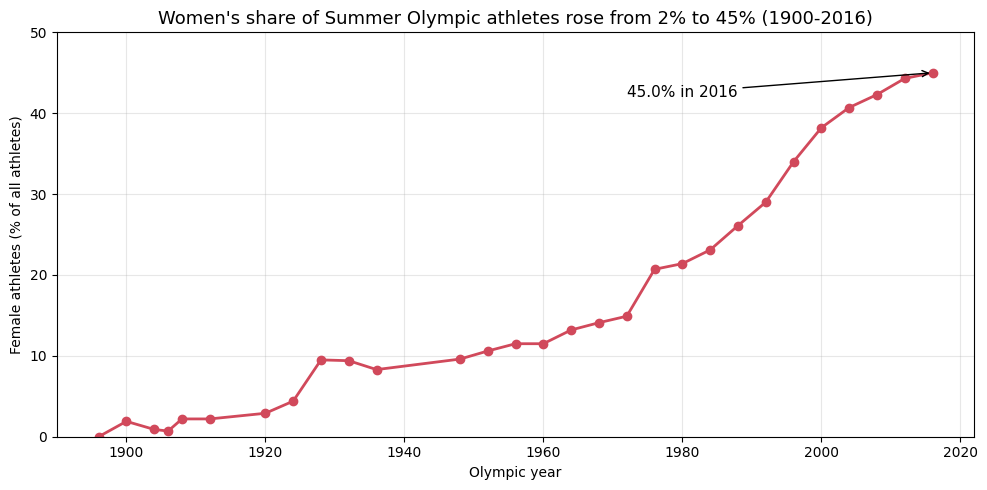

In [41]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(pct_female.index, pct_female.values, marker="o", color=F_COLOUR, linewidth=2)

last = pct_female.loc[2016]
ax.annotate(f"{last}% in 2016", xy=(2016, last), xytext=(1972, 42),
            arrowprops=dict(arrowstyle="->"), fontsize=11)

ax.set_title("Women's share of Summer Olympic athletes rose from 2% to 45% (1900-2016)", fontsize=13)
ax.set_xlabel("Olympic year")
ax.set_ylabel("Female athletes (% of all athletes)")
ax.set_ylim(0, 50)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../images/q1_female_participation.png", dpi=150)
plt.show()

**Finding:** Women went from under 2% of Summer athletes in 1900 to 45% in 2016. Growth was steady rather than sudden, and fastest between 1980 and 2000 (21% to 38%)


# Chart 2 (Q2): line chart, height and weight by decade

In [44]:
sns.set_theme(style="whitegrid")

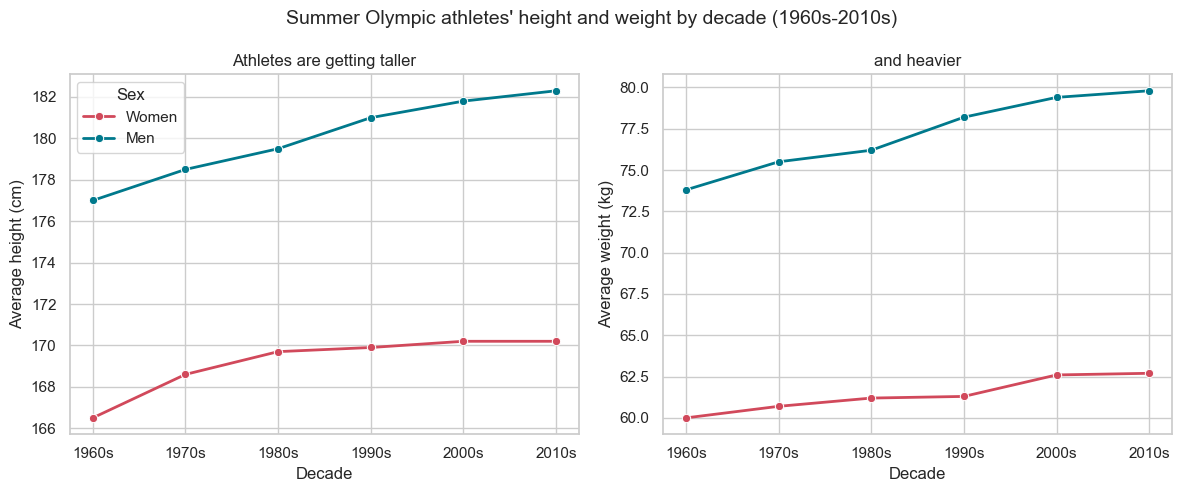

In [47]:

t = trend.reset_index()
t["Sex"] = t["Sex"].astype(str).map({"F": "Women", "M": "Men"})
palette = {"Women": F_COLOUR, "Men": M_COLOUR}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.lineplot(data=t, x="Decade", y="Height", hue="Sex", palette=palette,
             marker="o", linewidth=2, ax=axes[0])
sns.lineplot(data=t, x="Decade", y="Weight", hue="Sex", palette=palette,
             marker="o", linewidth=2, legend=False, ax=axes[1])

axes[0].set_title("Athletes are getting taller")
axes[0].set_ylabel("Average height (cm)")
axes[1].set_title("and heavier")
axes[1].set_ylabel("Average weight (kg)")

for ax in axes:
    ax.set_xlabel("Decade")
    ax.set_xticks(sorted(t["Decade"].unique()))
    ax.set_xticklabels([f"{d}s" for d in sorted(t["Decade"].unique())])

fig.suptitle("Summer Olympic athletes' height and weight by decade (1960s-2010s)", fontsize=14)

plt.tight_layout()
plt.savefig("../images/q2_physique_trend.png", dpi=150)
plt.show()

**Finding:** Men grew about 5 cm (177.0 to 182.3) and 6 kg; women about 4 cm (166.5 to 170.2) and 3 kg. BMI barely changed (men 23.5 to 23.9, women 21.6 to 21.5), so athletes grew in proportion rather than getting bulkier. Part of this may be a change in which sports are included, not only bodies changing.

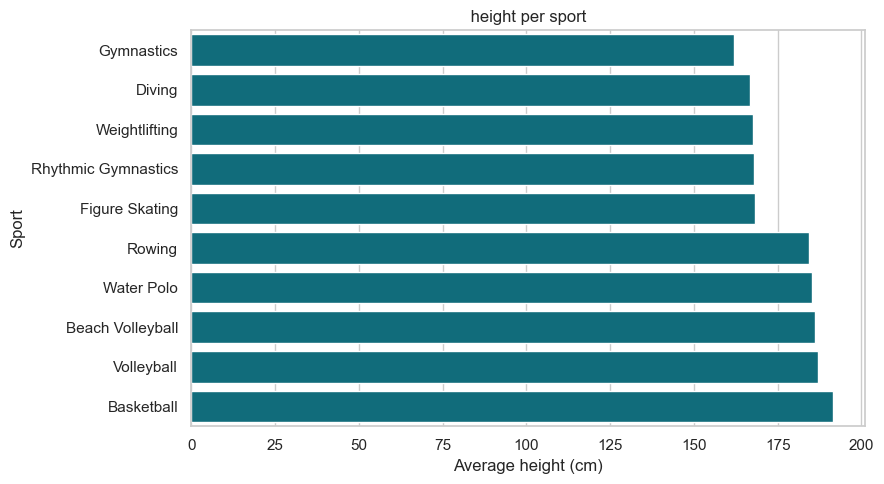

In [54]:
extremes = pd.concat([by_sport.head(5), by_sport.tail(5)]).reset_index()   # 5 shortest + 5 tallest

plt.figure(figsize=(9, 5))
sns.barplot(data=extremes, x="height", y="Sport", color=M_COLOUR, order=extremes["Sport"].tolist())
plt.title(" height per sport ")
plt.xlabel("Average height (cm)")
plt.ylabel("Sport")
plt.tight_layout()
plt.savefig("../images/q2b_height_by_sport.png", dpi=150)
plt.show()

**Finding:** Basketball players are the tallest on average (191 cm) and gymnasts the shortest (162 cm). Rowing, water polo and volleyball also average 185 cm or more, while diving, weightlifting and figure skating sit under 170 cm. Limitation: these averages combine men and women, and sports with more women (gymnastics) will look shorter for that reason alone.

# Q3: medal share by country and era (heatmap)

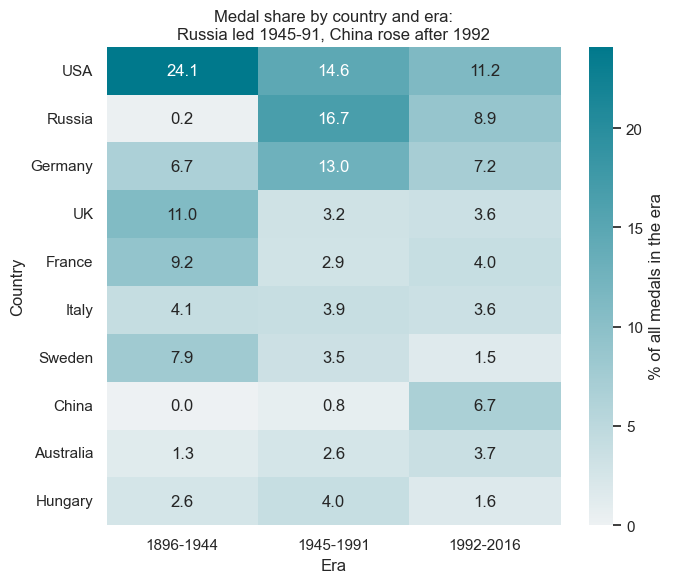

In [50]:
# Each country's share of ALL medals awarded in each era
era_counts["share"] = (era_counts["medals"]
                       / era_counts.groupby("Era", observed=True)["medals"].transform("sum") * 100)

top10 = medals["Country"].value_counts().head(10).index        # the 10 biggest medal winners
table = (era_counts[era_counts["Country"].isin(top10)]
         .pivot_table(index="Country", columns="Era", values="share", observed=True)
         .loc[top10]
         .fillna(0))                                           # 0 where a country won nothing in that era

plt.figure(figsize=(7, 6))
sns.heatmap(table, annot=True, fmt=".1f", cmap=sns.light_palette(M_COLOUR, as_cmap=True),
            cbar_kws={"label": "% of all medals in the era"})
plt.title("Medal share by country and era:\nRussia led 1945-91, China rose after 1992")
plt.xlabel("Era")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig("../images/q3_medal_share_heatmap.png", dpi=150)
plt.show()

**Finding:** The USA dominated the first era (24.1% of all medals) and still leads the latest (11.2%), though its share has halved. Russia (the USSR) was the top medal winner from 1945 to 1991 (16.7% vs the USA's 14.6%). China went from 0.8% to 6.7% after 1992. Note that "Russia" includes the USSR and "Germany" includes East and West Germany.

# Q4: age in the youngest and oldest sports (box plot)

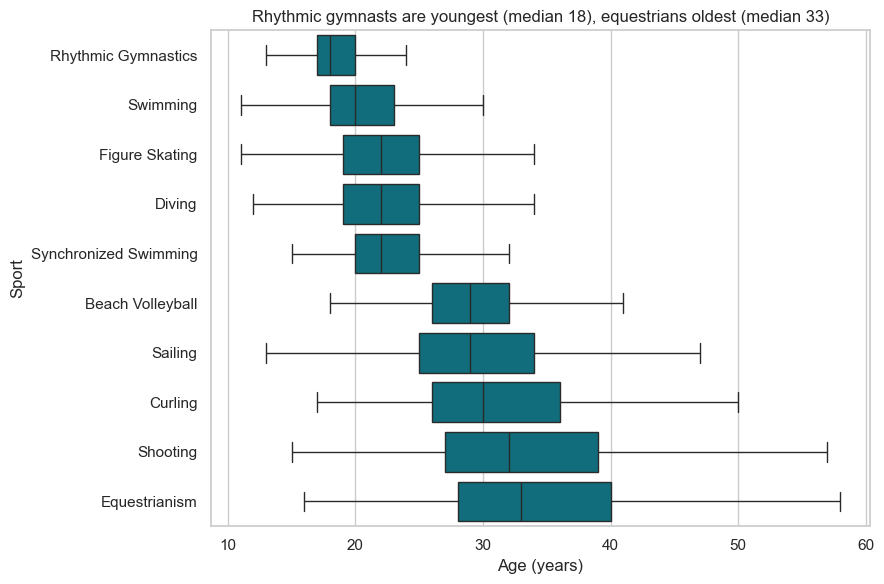

In [51]:
extremes = list(age_by_sport.head(5).index) + list(age_by_sport.tail(5).index)   # 5 youngest + 5 oldest
subset = age[age["Sport"].isin(extremes)]

plt.figure(figsize=(9, 6))
sns.boxplot(data=subset, x="Age", y="Sport", order=extremes, color=M_COLOUR, showfliers=False)
plt.title("Rhythmic gymnasts are youngest (median 18), equestrians oldest (median 33)")
plt.xlabel("Age (years)")
plt.ylabel("Sport")
plt.tight_layout()
plt.savefig("../images/q4_age_by_sport.png", dpi=150)
plt.show()

**Finding:** Among the 47 sports with 300+ athletes, median age runs from 18 (rhythmic gymnastics) to 33 (equestrianism). The youngest five (rhythmic gymnastics, swimming, figure skating, diving, synchronised swimming) reward flexibility and an early peak; the oldest five (beach volleyball, sailing, curling, shooting, equestrianism) reward precision and experience.

# Q5: home advantage (bar chart)

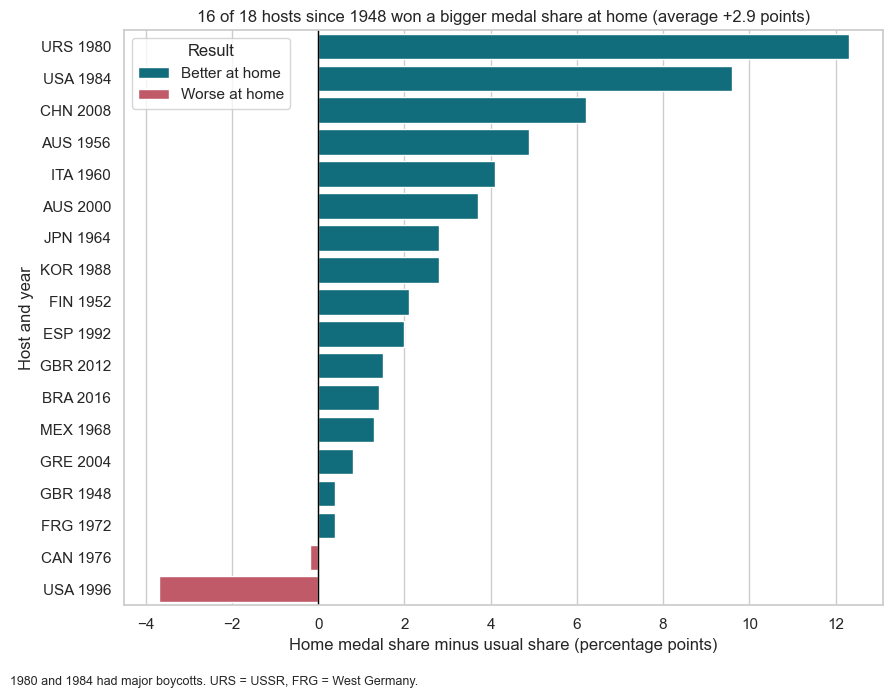

In [52]:
m = home[home["Games"].str[:4].astype(int) >= 1948].copy()      # modern Games only
m["label"] = m["Host"] + " " + m["Games"].str[:4]
m["Result"] = np.where(m["uplift"] > 0, "Better at home", "Worse at home")
m = m.sort_values("uplift", ascending=False)

plt.figure(figsize=(9, 7))
sns.barplot(data=m, x="uplift", y="label", hue="Result", dodge=False,
            palette={"Better at home": M_COLOUR, "Worse at home": F_COLOUR})
plt.axvline(0, color="black", linewidth=1)                       # the "no change" line
plt.title("16 of 18 hosts since 1948 won a bigger medal share at home (average +2.9 points)")
plt.xlabel("Home medal share minus usual share (percentage points)")
plt.ylabel("Host and year")
plt.figtext(0.01, 0.01, "1980 and 1984 had major boycotts. URS = USSR, FRG = West Germany.", fontsize=9)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("../images/q5_home_advantage.png", dpi=150)
plt.show()

**Finding:** 16 of 18 hosts since 1948 won a larger medal share at home, by 2.9 percentage points on average. The two biggest gains, USSR 1980 (+12.3) and USA 1984 (+9.6), came at boycotted Games, so reduced competition explains part of them. Only the USA in 1996 (-3.7) and Canada in 1976 (-0.2) did worse at home. Games before 1948 are excluded because few countries attended and hosts dominated.